# Estudio de mercado de gimnasios en EE. UU.
## Análisis exploratorio de datos por condado

Este cuaderno hace el análisis exploratorio de los condados de Estados Unidos para estudiar la oferta de gimnasios (NAICS 713940). Describo los datos, los limpio, selecciono las variables de entrada y agrupo los condados por perfil de cara al modelado.

**Contenido**

1. Carga de datos
2. Descripción del dataset
3. Limpieza y preparación de los datos
4. Variables de entrada
5. Variable objetivo
6. Relación de las variables con el objetivo
7. Geografía: región y estado
8. Selección de variables
9. Preparación para la clusterización
10. Clusterización de los condados
11. Resultados

# 0. Configuración del entorno

In [ ]:
#Ruta de la carpeta con los datos (instrucciones de descarga en el README)
ruta = "data/"

#En Google Colab: monta Drive y cambia `ruta` a la carpeta donde tengas los datos
#from google.colab import drive
#drive.mount("/content/drive")
#!pip install geopandas

import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import plotly.express as px
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Carga de datos

## 1.1 Gimnasios por condado (CBP)

In [ ]:
#Cargo el dataset de CBP (County Business Patterns) que cuenta el número de negocios por tipo y condado en Estados Unidos
cbp = pd.read_csv(ruta + "cbp23co.zip", dtype=str, encoding="latin-1")
cbp.columns = cbp.columns.str.lower()

gimnasios = cbp[cbp["naics"] == "713940"].copy() #Creo un dataframe filtrando por el código que coincide con el tipo de servicio de gimnasios
gimnasios["fips"] = gimnasios["fipstate"] + gimnasios["fipscty"] #Creo el fips( identificador compuesto por id de estado y condado)
gimnasios["est"] = pd.to_numeric(gimnasios["est"]) #Número de establecimientos
gimnasios = gimnasios[["fips", "est"]].rename(columns={"est": "gimnasios"})
gimnasios.head()

,fips,gimnasios
294,01001,9
1142,01003,28
1820,01009,5
2574,01015,7
3292,01021,4


## 1.2 Datos sociodemográficos (ACS)

In [ ]:
#Esta función es para cargar los datos de ACS(American Community Survey) que se basa en encuestas realizadas a la sociedad americana
def cargar_acs(nombre):
    with open(ruta + nombre + ".json") as f:
        filas = json.load(f)
    df = pd.DataFrame(filas[1:], columns=filas[0])   #primera fila = cabeceras
    df = df.loc[:, ~df.columns.duplicated()]       #quita la NAME repetida
    df["fips"] = df["state"] + df["county"]      #crea la clave
    return df
#Cargo los datos de acs
dp02 = cargar_acs("DP02")
dp03 = cargar_acs("DP03")
dp04 = cargar_acs("DP04")
dp05 = cargar_acs("DP05")

In [ ]:
#Nos quedamos de cada dataframe con el nombre (condado,estado), el fips y los que empiezan con E (estimaciones)
cols02 = ["fips", "NAME"] + [c for c in dp02.columns if c.startswith("DP02") and c.endswith("E")]
cols03 = ["fips"] + [c for c in dp03.columns if c.startswith("DP03") and c.endswith("E")]
cols04 = ["fips"] + [c for c in dp04.columns if c.startswith("DP04") and c.endswith("E")]
cols05 = ["fips"] + [c for c in dp05.columns if c.startswith("DP05") and c.endswith("E")]

acs = (
    dp02[cols02]
    .merge(dp03[cols03], on="fips", how="left")
    .merge(dp04[cols04], on="fips", how="left")
    .merge(dp05[cols05], on="fips", how="left")
)

## 1.3 Superficie de los condados

In [ ]:
#Cargo Cartographic Boundary Files 2024 (Censo de EE. UU.): contornos de los condados a escala 1:500.000; aporta la superficie (ALAND, en m²) para calcular la densidad de población y para dibujar mapas.
geo = gpd.read_file(ruta + "cb_2024_us_county_500k.zip")
area = geo[["GEOID", "ALAND"]].rename(columns={"GEOID": "fips"})
area.head()

,fips,ALAND
0,01069,1501742250
1,01023,2365900084
2,01113,1660653961
3,10005,2424590442
4,01071,2792044612


## 1.4 Limpieza de ACS y unión de los datos

In [ ]:
#Hay columnas en acs con valores negativos o que se interpretan como texto, voy a arreglarlo

#Cojo las columnas con variables numéricas para filtrar después
numericas = acs.columns.drop(["fips", "NAME"])

#Paso a numéricos las columnas que se habían interpretado como texto para poder trabajar con los datos, los datos que den error se quedarán como Nan
acs[numericas] = acs[numericas].apply(pd.to_numeric, errors="coerce")

#Los datos en negativo significa que es un dato no disponible por tanto los paso a NaN
acs[numericas] = acs[numericas].mask(acs[numericas] < 0)

In [ ]:
#Creo el dataframe que utilizaré finalmente con los datos de sociedad, servicios y estados
datos = ( acs.merge(gimnasios, on="fips", how="left").merge(area, on="fips", how="left"))

#Relleno las columnas de condados en los que no hay gimnasios con 0
datos["gimnasios"] = datos["gimnasios"].fillna(0)

# 2. Descripción del dataset

## 2.1 Dimensiones del dataframe

In [ ]:
print(datos.shape)
print("Condados sin gimnasios:", (datos["gimnasios"] == 0).sum())
print("Condados sin superficie:", datos["ALAND"].isna().sum())

(3222, 1088)
Condados sin gimnasios: 1908
Condados sin superficie: 0


In [ ]:
print(datos.columns.tolist())

['fips', 'NAME', 'DP02_0001E', 'DP02_0001PE', 'DP02_0002E', 'DP02_0002PE', 'DP02_0003E', 'DP02_0003PE', 'DP02_0004E', 'DP02_0004PE', 'DP02_0005E', 'DP02_0005PE', 'DP02_0006E', 'DP02_0006PE', 'DP02_0007E', 'DP02_0007PE', 'DP02_0008E', 'DP02_0008PE', 'DP02_0009E', 'DP02_0009PE', 'DP02_0010E', 'DP02_0010PE', 'DP02_0011E', 'DP02_0011PE', 'DP02_0012E', 'DP02_0012PE', 'DP02_0013E', 'DP02_0013PE', 'DP02_0014E', 'DP02_0014PE', 'DP02_0015E', 'DP02_0015PE', 'DP02_0016E', 'DP02_0016PE', 'DP02_0017E', 'DP02_0017PE', 'DP02_0018E', 'DP02_0018PE', 'DP02_0019E', 'DP02_0019PE', 'DP02_0020E', 'DP02_0020PE', 'DP02_0021E', 'DP02_0021PE', 'DP02_0022E', 'DP02_0022PE', 'DP02_0023E', 'DP02_0023PE', 'DP02_0024E', 'DP02_0024PE', 'DP02_0025E', 'DP02_0025PE', 'DP02_0026E', 'DP02_0026PE', 'DP02_0027E', 'DP02_0027PE', 'DP02_0028E', 'DP02_0028PE', 'DP02_0029E', 'DP02_0029PE', 'DP02_0030E', 'DP02_0030PE', 'DP02_0031E', 'DP02_0031PE', 'DP02_0032E', 'DP02_0032PE', 'DP02_0033E', 'DP02_0033PE', 'DP02_0034E', 'DP02_0034PE

## 2.2 Descripción de las variables

El dataframe `datos` tiene una fila por condado (3.222, con Puerto Rico) y 1.088 columnas:

| Columna | Descripción | Fuente |
|---|---|---|
| `fips` | Código de 5 cifras del condado (2 de estado + 3 de condado). Clave de unión | Todas |
| `NAME` | Nombre del condado y estado | ACS |
| `DP02_xxxx` a `DP05_xxxx` | 542 variables sociales, económicas, de vivienda y demográficas | ACS 2020-2024 |
| `gimnasios` | Nº de gimnasios y centros deportivos (NAICS 713940) con empleados. **Variable objetivo** | CBP 2023 |
| `ALAND` | Superficie de tierra del condado (m²) | Shapefile de contornos 2024 |

**Cómo se repiten las variables de ACS:** cada variable aparece dos veces, con el sufijo `E` (estimación, valor absoluto) y `PE` (porcentaje). Por ejemplo, `DP05_0001E` es la población total y `DP05_0001PE` es su versión en porcentaje. Son 542 variables distintas y 1.084 columnas. Se descartaron los márgenes de error (`M`, `PM`) y las anotaciones, porque miden la fiabilidad del dato y no el fenómeno que se quiere explicar.

### Contenido de las tablas de ACS

| Tabla | Tema | Variables | Bloques principales |
|---|---|---|---|
| **DP02** | Características sociales | 154 | Hogares por tipo, estado civil, fecundidad, matrícula escolar, nivel educativo, veteranos, discapacidad, residencia hace un año, lugar de nacimiento, ciudadanía, idioma, ascendencia, ordenadores e internet |
| **DP03** | Características económicas | 137 | Situación laboral, desplazamiento al trabajo, ocupación, sector de actividad, tipo de trabajador, renta y prestaciones, seguro de salud, pobreza |
| **DP04** | Vivienda | 143 | Ocupación, tipo de edificio, año de construcción, habitaciones, propiedad o alquiler, vehículos, calefacción, valor de la vivienda, hipoteca y costes, alquiler |
| **DP05** | Demografía | 108 | Sexo y edad, raza, origen hispano o latino, total de viviendas, población ciudadana en edad de votar |

### Variables más relevantes para el estudio

| Tema | Tabla | Por qué influye en el número de gimnasios |
|---|---|---|
| Población total | DP05 | Más habitantes, más clientes potenciales |
| Grupos de edad (20-44) | DP05 | Es el grupo que más usa gimnasios |
| Renta mediana del hogar | DP03 | La cuota es un gasto discrecional |
| Nivel educativo | DP02 | Se asocia con más hábito de ejercicio |
| Empleo | DP03 | Más población ocupada, más socios potenciales |
| Tipo de vivienda y hogares | DP02, DP04 | Indican si la zona es urbana o rural |

# 3. Limpieza y preparación de los datos

## 3.1 Columnas constantes

Antes de nada veamos qué columnas realmente nos interesan. Para decidir con cuáles me quedo empiezo por ver las que no varían.

In [ ]:
# Columnas con un único valor no nulo o 0
columnas_constantes = datos.columns[datos.nunique(dropna=True) <= 1]

print(columnas_constantes.tolist())

['DP02_0016PE', 'DP02_0017PE', 'DP02_0039PE', 'DP02_0040PE', 'DP02_0041PE', 'DP02_0042PE', 'DP02_0043PE', 'DP03_0009E', 'DP03_0025PE', 'DP03_0062PE', 'DP03_0063PE', 'DP03_0065PE', 'DP03_0067PE', 'DP03_0069PE', 'DP03_0071PE', 'DP03_0073PE', 'DP03_0086PE', 'DP03_0087PE', 'DP03_0088PE', 'DP03_0090PE', 'DP03_0091PE', 'DP03_0092PE', 'DP03_0093PE', 'DP03_0094PE', 'DP03_0119E', 'DP03_0120E', 'DP03_0121E', 'DP03_0122E', 'DP03_0123E', 'DP03_0124E', 'DP03_0125E', 'DP03_0126E', 'DP03_0127E', 'DP03_0128E', 'DP03_0129E', 'DP03_0130E', 'DP03_0131E', 'DP03_0132E', 'DP03_0133E', 'DP03_0134E', 'DP03_0135E', 'DP03_0136E', 'DP03_0137E', 'DP04_0004PE', 'DP04_0005PE', 'DP04_0037PE', 'DP04_0048PE', 'DP04_0049PE', 'DP04_0089PE', 'DP04_0101PE', 'DP04_0109PE', 'DP04_0116PE', 'DP04_0125PE', 'DP04_0134PE', 'DP04_0135PE', 'DP04_0143PE', 'DP05_0004PE', 'DP05_0018PE', 'DP05_0028PE', 'DP05_0032PE', 'DP05_0105PE']


Veamos si alguna de ellas es nula.

In [ ]:
#Por cada columna muestro el número de veces que se repite cada dato
for col in columnas_constantes:
    print(f"\n{col}")
    print(datos[col].value_counts(dropna=False).head())


DP02_0016PE
DP02_0016PE
NaN    3222
Name: count, dtype: int64

DP02_0017PE
DP02_0017PE
NaN    3222
Name: count, dtype: int64

DP02_0039PE
DP02_0039PE
NaN    3222
Name: count, dtype: int64

DP02_0040PE
DP02_0040PE
NaN    3222
Name: count, dtype: int64

DP02_0041PE
DP02_0041PE
NaN    3222
Name: count, dtype: int64

DP02_0042PE
DP02_0042PE
NaN    3222
Name: count, dtype: int64

DP02_0043PE
DP02_0043PE
NaN    3222
Name: count, dtype: int64

DP03_0009E
DP03_0009E
NaN    3222
Name: count, dtype: int64

DP03_0025PE
DP03_0025PE
NaN    3222
Name: count, dtype: int64

DP03_0062PE
DP03_0062PE
NaN    3222
Name: count, dtype: int64

DP03_0063PE
DP03_0063PE
NaN    3222
Name: count, dtype: int64

DP03_0065PE
DP03_0065PE
NaN    3222
Name: count, dtype: int64

DP03_0067PE
DP03_0067PE
NaN    3222
Name: count, dtype: int64

DP03_0069PE
DP03_0069PE
NaN    3222
Name: count, dtype: int64

DP03_0071PE
DP03_0071PE
NaN    3222
Name: count, dtype: int64

DP03_0073PE
DP03_0073PE
NaN    3222
Name: count, dtype: 

Las columnas nulas coinciden con las `PE` cuyas `E` están basadas en medias y medianas, por tanto me deshago de ellas porque no son necesarias.

In [ ]:
datos = datos.drop(columns=columnas_constantes)

In [ ]:
print(datos.shape)

(3222, 1027)


## 3.2 Condados de Puerto Rico

Quito los datos de ACS de Puerto Rico porque CBP no los incluye.

In [ ]:
datos = datos[datos["fips"].str[:2] != "72"].copy()
print(datos.shape)    # esperado: 3144 filas

(3144, 1027)


## 3.3 Selección de variables de entrada

Dada la cantidad de variables de entrada no necesarias en el dataset he hecho una limpieza de variables por criterio propio, dejando las que pueden guardar una relación por razones económicas, demográficas y geográficas. Por tanto, las restantes son las siguientes:

| Código ACS | Variable en el dataframe | Descripción | Motivo |
|---|---|---|---|
| `DP05_0001E` | `poblacion_total` | Población total | Más gente más clientes |
| `DP02_0001E` | `num_hogares` | Número de hogares | Gasto por hogar |
| `DP05_0018E` | `edad_mediana` | Edad mediana | Punto medio de la edad |
| `DP05_0009PE` | `pct_20_24` | Porcentaje población 20 a 24 años | Jóvenes y universitarios |
| `DP05_0010PE` | `pct_25_34` | Porcentaje población 25 a 34 años | Público objetivo central |
| `DP05_0011PE` | `pct_35_44` | Porcentaje población 35 a 44 años | Adultos con mayores ingresos |
| `DP05_0024PE` | `pct_65_mas` | Porcentaje mayores de 65 | Posible relación negativa |
| `DP03_0062E` | `renta_mediana_hogar` | Renta mediana del hogar | Ver si hay relación directa |
| `DP03_0088E` | `renta_per_capita` | Renta per cápita | Capacidad de gasto individual |
| `DP03_0128PE` | `pct_pobreza` | Porcentaje de personas bajo umbral de pobreza | - |
| `DP02_0068PE` | `pct_universitarios` | Porcentaje personas con estudios superiores | - |
| `DP02_0058PE` | `pct_matriculados_univ` | Porcentaje personas matriculadas en universidad | Posible alta relación |
| `DP03_0004PE` | `pct_empleados` | Porcentaje población empleada | - |
| `DP03_0009PE` | `tasa_paro` | Paro en porcentaje | - |
| `DP03_0027PE` | `pct_ocup_profesionales` | Porcentaje en ocupaciones de gestión, ciencia y artes | Perfiles de alto ingreso |
| `DP03_0024PE` | `pct_teletrabajo` | Porcentaje población que trabaja en casa | Necesidad de hacer ejercicio |
| `DP02_0016E` | `tamaño_medio_hogar` | Tamaño medio de hogar | Jóvenes suelen vivir solos frente a familias |
| `DP04_0047PE` | `pct_viviendas_alquiler` | Porcentaje viviendas de alquiler | Población más móvil y joven |
| `DP04_0013PE` | `pct_edificios_20_mas` | Porcentaje viviendas en edificios de 20 o más | - |
| `DP04_0058PE` | `pct_sin_vehiculo` | Porcentaje de hogares sin coche | En zonas urbanas se usa menos el coche |
| `DP04_0089E` | `valor_mediano_vivienda` | Valor mediano de vivienda | Nivel de riqueza y zonas caras |
| `DP04_0134E` | `alquiler_mediano` | Valor mediano de alquiler | - |
| `DP02_0154PE` | `pct_banda_ancha` | Porcentaje de hogares con conexión de banda ancha | Entornos desarrollados |
| Calculada con `DP05_0001E` y `ALAND` | `densidad` | Habitantes por km² | Distinción de urbano y rural |

In [ ]:
#Creo la variable de densidad (habitantes por km²) usando los datos de ALAND
datos["densidad"] = datos["DP05_0001E"] / (datos["ALAND"] / 1_000_000)

In [ ]:
entradas = [
    "DP05_0001E", "DP02_0001E", "DP05_0018E", "DP05_0009PE", "DP05_0010PE", "DP05_0011PE",
    "DP05_0024PE", "DP03_0062E", "DP03_0088E", "DP03_0128PE", "DP02_0068PE", "DP02_0058PE",
    "DP03_0004PE", "DP03_0009PE", "DP03_0027PE", "DP03_0024PE", "DP02_0016E", "DP04_0047PE",
    "DP04_0013PE", "DP04_0058PE", "DP04_0089E", "DP04_0134E", "DP02_0154PE", "densidad",
]

nombres = {
    "DP05_0001E": "poblacion_total",        "DP02_0001E": "num_hogares",
    "DP05_0018E": "edad_mediana",           "DP05_0009PE": "pct_20_24",
    "DP05_0010PE": "pct_25_34",             "DP05_0011PE": "pct_35_44",
    "DP05_0024PE": "pct_65_mas",            "DP03_0062E": "renta_mediana_hogar",
    "DP03_0088E": "renta_per_capita",       "DP03_0128PE": "pct_pobreza",
    "DP02_0068PE": "pct_universitarios",    "DP02_0058PE": "pct_matriculados_univ",
    "DP03_0004PE": "pct_empleados",         "DP03_0009PE": "tasa_paro",
    "DP03_0027PE": "pct_ocup_profesionales","DP03_0024PE": "pct_teletrabajo",
    "DP02_0016E": "tamaño_medio_hogar",    "DP04_0047PE": "pct_viviendas_alquiler",
    "DP04_0013PE": "pct_edificios_20_mas",  "DP04_0058PE": "pct_sin_vehiculo",
    "DP04_0089E": "valor_mediano_vivienda", "DP04_0134E": "alquiler_mediano",
    "DP02_0154PE": "pct_banda_ancha",
}

df = datos[["fips", "NAME", "gimnasios"] + entradas].rename(columns=nombres)

print(df.shape)
df.head()

(3144, 27)


,fips,NAME,gimnasios,poblacion_total,num_hogares,edad_mediana,pct_20_24,pct_25_34,pct_35_44,pct_65_mas,...,pct_ocup_profesionales,pct_teletrabajo,tamaño_medio_hogar,pct_viviendas_alquiler,pct_edificios_20_mas,pct_sin_vehiculo,valor_mediano_vivienda,alquiler_mediano,pct_banda_ancha,densidad
0,01001,"Autauga County, Alabama",9.0,59947,22917.0,39.0,5.2,13.0,13.3,16.3,...,36.3,6.7,2.59,22.9,1.9,4.1,207200.0,1263.0,93.2,38.935941
1,01003,"Baldwin County, Alabama",28.0,246989,98574.0,43.9,4.9,11.0,12.1,21.7,...,37.5,11.6,2.47,22.4,12.4,2.7,316900.0,1277.0,90.6,59.981086
2,01005,"Barbour County, Alabama",0.0,24643,9128.0,40.8,5.3,13.5,12.8,20.1,...,27.1,6.5,2.37,31.8,1.0,10.5,112900.0,688.0,75.5,10.750994
3,01007,"Bibb County, Alabama",0.0,22130,7704.0,41.2,5.6,14.3,13.2,17.4,...,26.5,4.8,2.67,20.8,1.2,5.4,145700.0,733.0,82.9,13.726681
4,01009,"Blount County, Alabama",5.0,59518,22180.0,41.3,5.7,11.9,12.0,18.6,...,28.9,6.1,2.66,19.0,0.5,4.0,175200.0,776.0,85.0,35.633992


## 3.4 Valores nulos

Veamos qué filas tienen nulos.

In [ ]:
df[df.isna().any(axis=1)]

,fips,NAME,gimnasios,poblacion_total,num_hogares,edad_mediana,pct_20_24,pct_25_34,pct_35_44,pct_65_mas,...,pct_ocup_profesionales,pct_teletrabajo,tamaño_medio_hogar,pct_viviendas_alquiler,pct_edificios_20_mas,pct_sin_vehiculo,valor_mediano_vivienda,alquiler_mediano,pct_banda_ancha,densidad
188,06003,"Alpine County, California",0.0,1616,435.0,39.8,8.3,12.4,12.1,21.1,...,44.6,18.3,3.61,21.8,7.9,5.7,590200.0,NaN,90.6,0.845059
232,06091,"Sierra County, California",0.0,2746,1219.0,54.7,1.5,1.0,11.3,35.1,...,51.7,16.8,2.17,27.9,2.8,6.5,331900.0,NaN,79.5,1.112329
550,15005,"Kalawao County, Hawaii",0.0,67,40.0,39.5,0.0,20.9,38.8,20.9,...,6.1,6.1,1.15,100.0,0.0,15.0,NaN,1271.0,90.0,2.157282
1803,35011,"De Baca County, New Mexico",0.0,1576,820.0,35.3,3.5,26.1,8.4,26.6,...,21.5,3.6,1.90,28.5,0.0,5.6,187500.0,387.0,79.5,0.261932
2541,48033,"Borden County, Texas",0.0,713,243.0,32.2,4.1,14.2,11.5,17.3,...,39.6,9.7,2.93,33.7,0.0,1.2,108900.0,NaN,85.6,0.306750
2577,48105,"Crockett County, Texas",0.0,2822,1225.0,42.6,0.2,18.1,7.5,19.0,...,39.8,7.2,2.26,26.3,0.0,0.0,NaN,558.0,87.3,0.388121
2593,48137,"Edwards County, Texas",0.0,1290,404.0,39.0,7.2,0.6,14.3,18.4,...,19.6,14.0,3.09,12.1,0.0,7.9,NaN,713.0,69.3,0.235176
2655,48261,"Kenedy County, Texas",0.0,145,55.0,54.8,0.0,6.2,23.4,39.3,...,25.0,14.3,2.53,47.3,0.0,16.4,NaN,NaN,69.1,0.038384
2659,48269,"King County, Texas",0.0,211,111.0,49.4,0.0,21.8,11.4,30.8,...,49.0,14.0,1.90,40.5,0.0,6.3,52100.0,NaN,100.0,0.089439
2675,48301,"Loving County, Texas",0.0,33,27.0,86.2,6.1,0.0,0.0,81.8,...,76.9,0.0,1.22,88.9,6.1,7.4,NaN,NaN,92.6,0.019051


Los lugares con nulos coinciden con 11 condados muy pequeños en los que ACS no publica algunas medianas por falta de muestra, ninguno tiene gimnasios.

## 3.5 Tipos de datos y nuevas variables

En esta sección se dejan listas las columnas que se usarán en el análisis y se comprueba la integridad del dataset.

**`gimnasios` como entero.** El número de gimnasios es un recuento, no puede ser $9{,}5$. Al rellenar con $0$ los condados ausentes de CBP, pandas lo había convertido a decimal ($9{,}0$), así que lo paso a entero para que el tipo de dato refleje la naturaleza de la variable.

**`estado`.** Nueva variable categórica que se extrae del campo `NAME` (por ejemplo, "Autauga County, Alabama" pasa a "Alabama"). Todas las variables de entrada seleccionadas son numéricas, así que `estado` aporta la única variable categórica del dataset. Tiene dos usos:

- La oferta de gimnasios varía entre estados más allá de lo que explica la demografía, y esta columna permite capturarlo.
- Los condados vecinos son muy parecidos entre sí, por lo que en el modelado se validará agrupando por estado para evitar resultados optimistas.

**`tasa_10k`.** Gimnasios por cada $10\,000$ habitantes:

$$\text{tasa\_10k} = \frac{\text{gimnasios}}{\text{poblacion\_total}} \cdot 10\,000$$

El recuento bruto depende sobre todo del tamaño del condado, mientras que la tasa mide la oferta relativa, que es lo que interesa para detectar zonas con pocos gimnasios en relación con su población. Se usará para el análisis y los gráficos, pero no como variable de entrada del modelo, porque se calcula a partir de la variable objetivo y usarla como entrada supondría filtrar la respuesta al modelo.

**`grande`.** Condados con $25\,000$ habitantes o más, es decir, $\text{poblacion\_total} \geq 25\,000$. Una tasa por habitante en un condado pequeño es muy inestable: en uno de $800$ personas, un solo gimnasio equivale a más de $12$ por $10\,000$. Además, por debajo de ese tamaño casi todos los condados tienen $0$ gimnasios con empleados. Se usa como filtro para calcular y comparar tasas solo donde tienen sentido. Tampoco es una variable de entrada.

**Comprobaciones de calidad.** Verifico el tipo de dato de cada columna y los nulos, y compruebo que no hay `fips` repetidos, filas duplicadas ni nombres de condado repetidos. Se comprueba además que hay $51$ estados.

In [ ]:
df["gimnasios"] = df["gimnasios"].astype(int) #Transformo la variable gimnasios a int

df["estado"] = df["NAME"].str.split(", ").str[-1] #Nueva variable categórica

df['tasa_10k'] = df['gimnasios'] / df["poblacion_total"] * 10000 #Tasa de gimnasios por cada 10k habitantes

df['grande'] = df['poblacion_total'] >=25000 #Indica si habitan 25000 o más personas

df.info() #Nulos por columna
#Descripción calidad de datos:
print("Fips repetidos: ", df["fips"].duplicated().sum())
print("Filas totalmente duplicadas: ", df.duplicated().sum())
print("Nombres de condado repetidos: ", df['NAME'].duplicated().sum())
print("Estados distintos: ", df["estado"].nunique())

<class 'pandas.core.frame.DataFrame'>
Index: 3144 entries, 0 to 3143
Data columns (total 30 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   fips                    3144 non-null   object 
 1   NAME                    3144 non-null   object 
 2   gimnasios               3144 non-null   int64  
 3   poblacion_total         3144 non-null   int64  
 4   num_hogares             3144 non-null   float64
 5   edad_mediana            3144 non-null   float64
 6   pct_20_24               3144 non-null   float64
 7   pct_25_34               3144 non-null   float64
 8   pct_35_44               3144 non-null   float64
 9   pct_65_mas              3144 non-null   float64
 10  renta_mediana_hogar     3143 non-null   float64
 11  renta_per_capita        3144 non-null   int64  
 12  pct_pobreza             3144 non-null   float64
 13  pct_universitarios      3144 non-null   float64
 14  pct_matriculados_univ   3142 non-null   float

# 4. Variables de entrada

## 4.1 Distribución

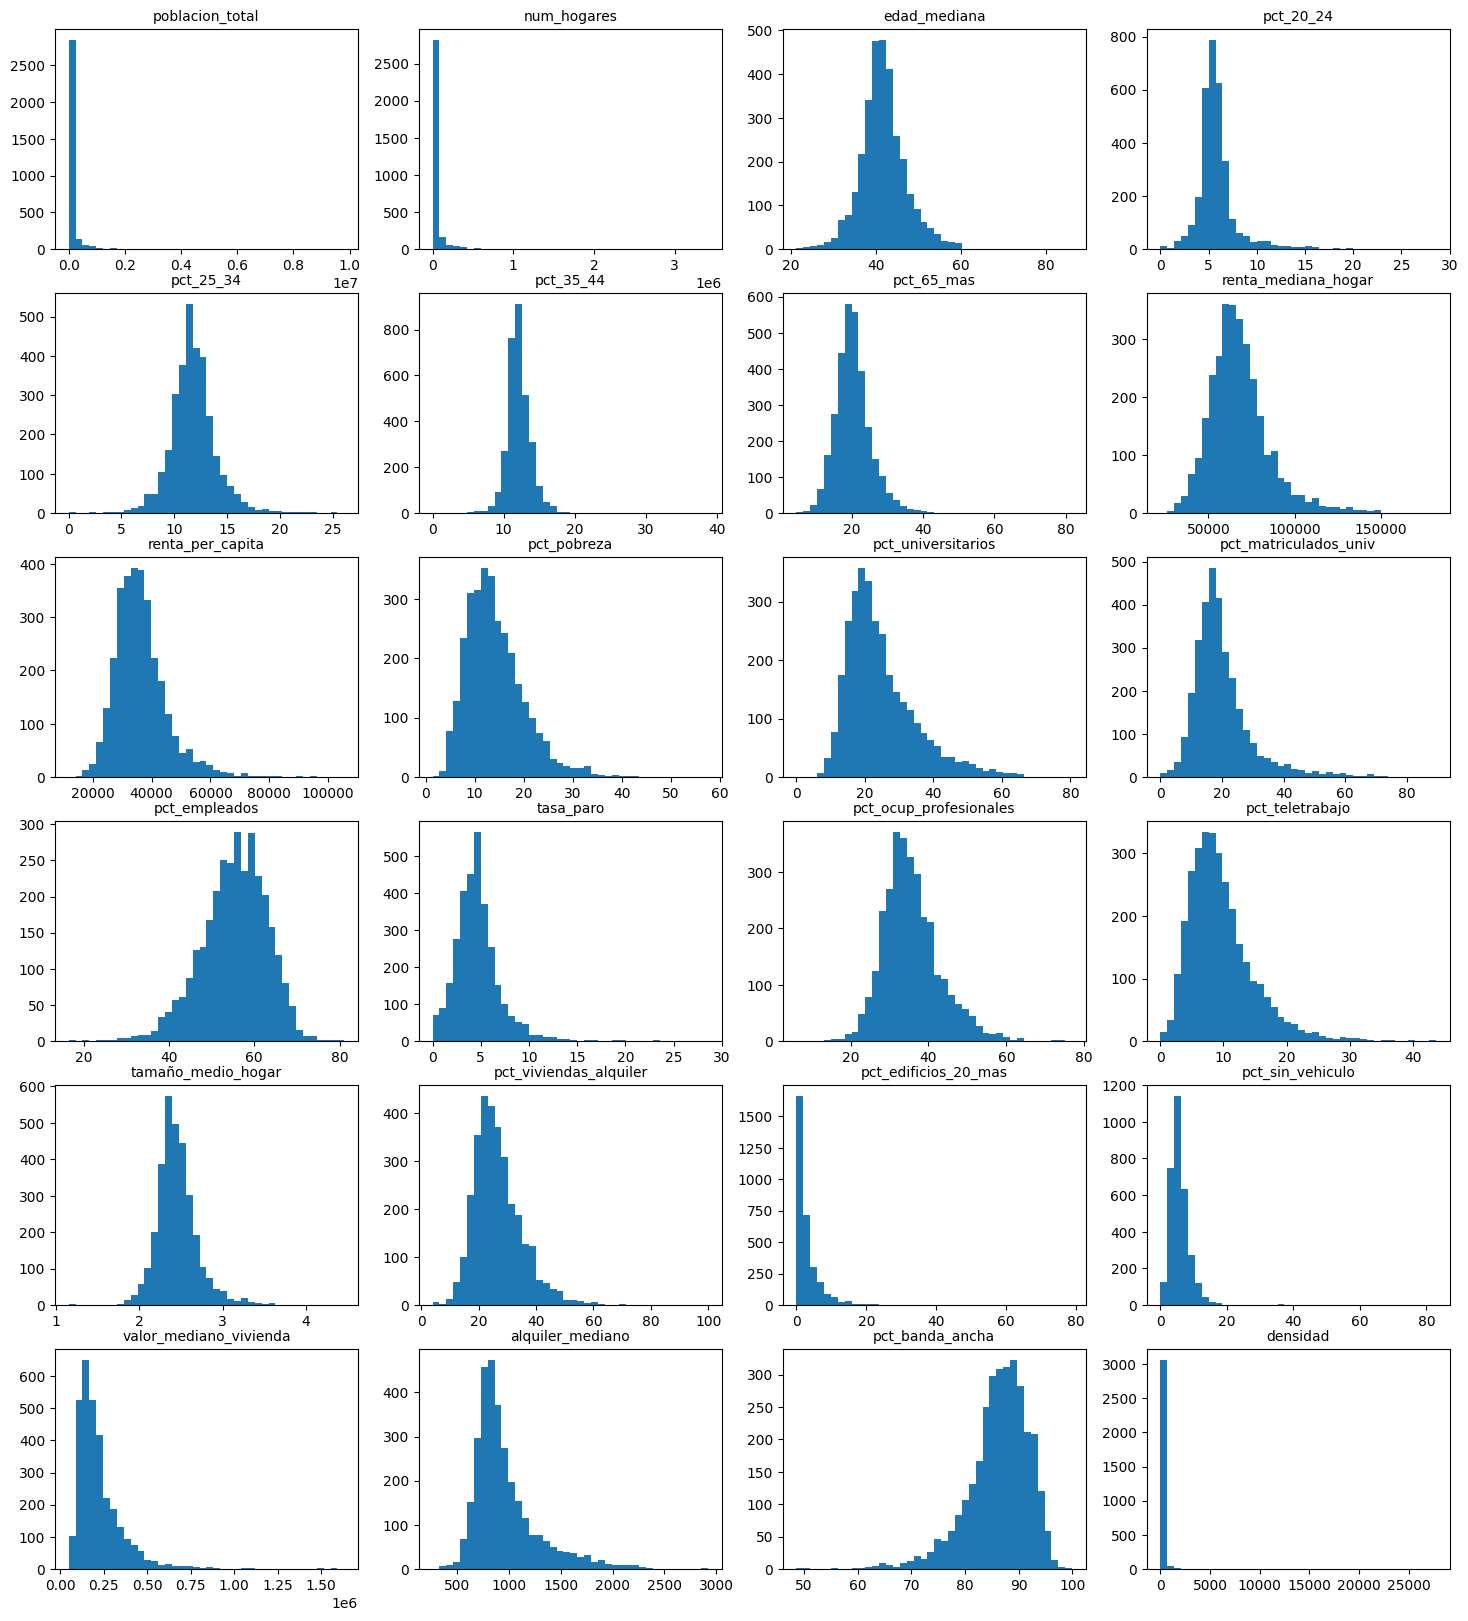

In [ ]:
variables = df.columns.drop(["fips", "NAME", "gimnasios", "estado", "tasa_10k", "grande"])

fig, ejes = plt.subplots(6, 4, figsize=(18, 20)) #Habrá 24 gráficos, uno por variable de entrada

for ax, var in zip(ejes.flatten(), variables): # flatten() convierte la matriz de gráficos 6x4 en una lista de 24 para que zip empareje cada gráfico con una variable
  ax.hist(df[var].dropna(), bins=40) #Histograma sin nulos de 40 barras
  ax.set_title(var, fontsize=10) #pongo de título el nombre de la variable

Los histogramas de las variables de entrada muestran dos grupos claros. Las variables de tamaño y estructura urbana (`poblacion_total`, `num_hogares`, `pct_edificios_20_mas` y `valor_mediano_vivienda`) están extremadamente sesgadas a la derecha: la gran mayoría de los condados son pequeños y rurales, y unos pocos muy grandes (como Los Ángeles) generan colas muy largas. Las variables demográficas y socioeconómicas (renta, pobreza, paro, educación, teletrabajo, alquiler) presentan un sesgo moderado a la derecha, mientras que `pct_banda_ancha` y `pct_empleados` lo tienen a la izquierda, y `edad_mediana`, `pct_25_34`, `pct_35_44`, `pct_65_mas` y `tamaño_medio_hogar` son casi simétricas. Además, aparecen algunos valores extremos aislados (por ejemplo en `pct_sin_vehiculo` o `pct_20_24`) que conviene revisar para decidir si son casos reales o estimaciones poco fiables de condados muy pequeños. En conjunto, esto indica que las variables de escala necesitarán una transformación logarítmica para los modelos lineales, mientras que el resto puede usarse tal cual, y que los extremos deben tratarse con cuidado en el modelado.

## 4.2 Asimetría

In [ ]:
#Sesgo de cada variable de entrada

sesgo = df[variables].skew()

print(sesgo)

poblacion_total           12.851602
num_hogares               11.807828
edad_mediana               0.474568
pct_20_24                  3.060735
pct_25_34                  0.571806
pct_35_44                  1.775361
pct_65_mas                 1.313405
renta_mediana_hogar        1.253754
renta_per_capita           1.571011
pct_pobreza                1.192807
pct_universitarios         1.291195
pct_matriculados_univ      2.033497
pct_empleados             -0.504583
tasa_paro                  1.837394
pct_ocup_profesionales     0.851727
pct_teletrabajo            1.364253
tamaño_medio_hogar         1.169692
pct_viviendas_alquiler     1.316562
pct_edificios_20_mas       5.144486
pct_sin_vehiculo           7.485626
valor_mediano_vivienda     3.131812
alquiler_mediano           1.704660
pct_banda_ancha           -1.200240
densidad                  26.387832
dtype: float64


Hay varias variables que demuestran una gran asimetría hacia la derecha, veamos cuáles se podrían solucionar con una escala logarítmica, $x \rightarrow \log(1+x)$. Uso $\log(1+x)$ y no $\log(x)$ porque algunas variables toman el valor $0$.

In [ ]:
sesgo_log = np.log1p(df[variables]).skew()

print(sesgo_log)

poblacion_total           0.257605
num_hogares               0.271606
edad_mediana             -0.251381
pct_20_24                -0.087528
pct_25_34                -2.188225
pct_35_44                -2.155265
pct_65_mas               -0.184728
renta_mediana_hogar       0.163967
renta_per_capita          0.326496
pct_pobreza              -0.085068
pct_universitarios        0.050620
pct_matriculados_univ    -0.620558
pct_empleados            -1.159018
tasa_paro                -0.653387
pct_ocup_profesionales   -0.093366
pct_teletrabajo          -0.304481
tamaño_medio_hogar        0.617657
pct_viviendas_alquiler   -0.128822
pct_edificios_20_mas      0.578794
pct_sin_vehiculo          0.188748
valor_mediano_vivienda    0.551017
alquiler_mediano          0.706942
pct_banda_ancha          -1.654525
densidad                  0.557186
dtype: float64


El log ayuda bastante en algunas variables sobre todo: densidad, población total, `num_hogares`, `pct_sin_vehiculo`, `pct_edificios_20_mas`.

Y en menor medida en `valor_mediano_vivienda`, `pct_20_24`, `tasa_paro`, `pct_matriculados_univ`, `alquiler_mediano`, `renta_per_capita`, `pct_teletrabajo`, `pct_viviendas_alquiler`, `pct_universitarios`, `pct_65_mas`, `renta_mediana_hogar`, `pct_pobreza`, `tamaño_medio_hogar`.

En cambio, en las variables `pct_35_44` y `pct_banda_ancha` aumentó el sesgo, y en `pct_25_34` y `pct_empleados` no era necesario porque no había una gran asimetría.

## 4.3 Transformación logarítmica

Por tanto, paso a escala logarítmica las variables que cumplen $|\text{asimetría}| > 1$ y cuya asimetría, en valor absoluto, disminuye tras aplicar $\log(1+x)$. Son las que detecté que se ven beneficiadas.

In [ ]:
#Extraigo las variables con sesgo mayor a  1 y las que quedan menores tras pasarlo por la función logarítmica (en valor absoluto)
vars_log = sesgo.index[(sesgo.abs() > 1) & ((sesgo_log.abs()) < sesgo.abs())].tolist()

for var in vars_log:
  df["log_"+ var] = np.log1p(df[var])

df.describe()

,gimnasios,poblacion_total,num_hogares,edad_mediana,pct_20_24,pct_25_34,pct_35_44,pct_65_mas,renta_mediana_hogar,renta_per_capita,...,log_pct_matriculados_univ,log_tasa_paro,log_pct_teletrabajo,log_tamaño_medio_hogar,log_pct_viviendas_alquiler,log_pct_edificios_20_mas,log_pct_sin_vehiculo,log_valor_mediano_vivienda,log_alquiler_mediano,log_densidad
count,3144.000000,3.144000e+03,3.144000e+03,3144.000000,3144.000000,3144.000000,3144.000000,3144.000000,3143.000000,3144.000000,...,3142.000000,3144.000000,3144.000000,3144.000000,3144.000000,3144.000000,3144.000000,3139.000000,3137.000000,3144.000000
mean,12.820293,1.065275e+05,4.110289e+04,41.838168,5.919656,11.793957,12.169911,20.440458,67976.429208,36364.775445,...,2.953710,1.648135,2.252683,1.236667,3.279270,1.089308,1.850136,12.195531,6.831757,3.010462
std,46.960329,3.351286e+05,1.243503e+05,5.412833,2.314794,2.260625,1.797164,5.080881,17774.483025,9195.005291,...,0.441150,0.429240,0.480707,0.069985,0.300306,0.754483,0.434444,0.504571,0.290404,1.572927
min,0.000000,3.300000e+01,2.700000e+01,21.400000,0.000000,0.000000,0.000000,4.500000,22188.000000,11771.000000,...,0.000000,0.000000,0.000000,0.765468,1.589235,0.000000,0.000000,10.791399,5.579730,0.013666
25%,0.000000,1.080500e+04,4.275250e+03,38.700000,4.900000,10.600000,11.200000,17.275000,56728.000000,30366.500000,...,2.721295,1.435085,1.945910,1.193922,3.091042,0.530628,1.609438,11.859709,6.645091,1.972805
50%,0.000000,2.596050e+04,1.032250e+04,41.500000,5.600000,11.700000,12.100000,20.000000,65681.000000,35133.500000,...,2.939162,1.686399,2.272126,1.232560,3.273364,1.029619,1.856298,12.129737,6.777647,2.908269
75%,7.000000,6.891225e+04,2.713150e+04,44.500000,6.400000,12.900000,13.000000,22.900000,75827.000000,40326.250000,...,3.186353,1.902108,2.564949,1.269761,3.468856,1.568616,2.091864,12.504327,6.975414,3.857474
max,1283.000000,9.808667e+06,3.416449e+06,86.200000,28.600000,26.100000,38.800000,81.800000,181765.000000,105496.000000,...,4.505350,3.387774,3.799974,1.697449,4.615121,4.380776,4.429626,14.306481,7.980366,10.231641


# 5. Variable objetivo

Voy a observar cómo se comporta la variable objetivo (`gimnasios`).

In [ ]:
print(df['gimnasios'].describe())

count    3144.000000
mean       12.820293
std        46.960329
min         0.000000
25%         0.000000
50%         0.000000
75%         7.000000
max      1283.000000
Name: gimnasios, dtype: float64


La media es $\mu = 12{,}82$ y, en cambio, la desviación típica es muy elevada ($\sigma = 46{,}96$), lo que muestra una dispersión enorme. Podemos observarlo a continuación.

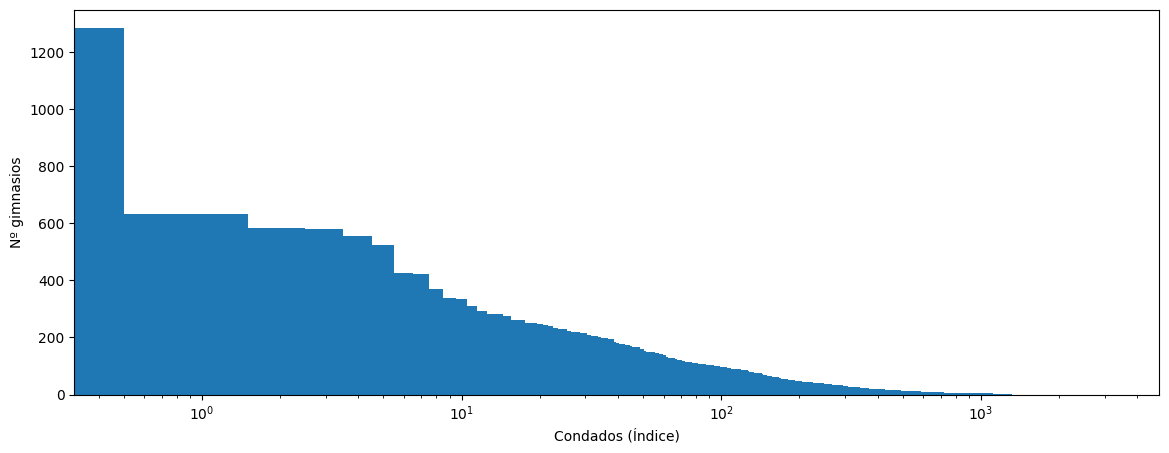

In [ ]:
gimnasios_desc = df.sort_values("gimnasios", ascending=False).reset_index()

plt.figure(figsize=(14,5))
plt.bar(gimnasios_desc.index, gimnasios_desc["gimnasios"], width=1)

plt.xlabel("Condados (Índice)")
plt.ylabel("Nº gimnasios")
plt.xscale("log")
plt.show()

Cantidad de filas con 0 en gimnasios:  1830


Text(0.5, 1.0, 'tasa_10k (condados grandes)')

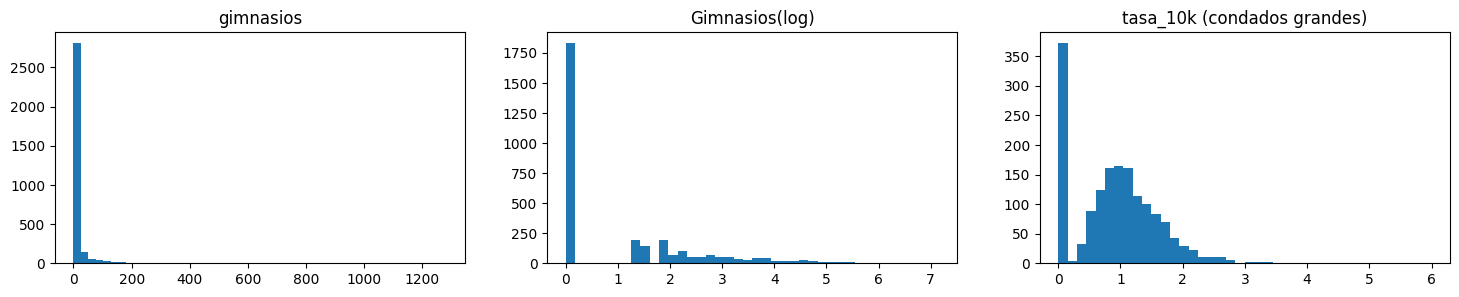

In [ ]:
#Veamos la cantidad de ceros en la variable objetivo
ceros = (df['gimnasios'] == 0).sum()
print("Cantidad de filas con 0 en gimnasios: ", ceros)

fig, ejes = plt.subplots(1, 3, figsize=(18,3))

ejes[0].hist(df["gimnasios"], bins=50)                    # conteo normal
ejes[0].set_title("gimnasios")

ejes[1].hist(np.log1p(df["gimnasios"]), bins=40)          # log1p abre la zona de valores pequeños
ejes[1].set_title("Gimnasios(log)")

ejes[2].hist(df.loc[df["grande"], "tasa_10k"], bins=40)   # solo condados con más de 25k habitantes
ejes[2].set_title("tasa_10k (condados grandes)")

In [ ]:
#Calculo algunos datos para describir la variable objetivo
print("Porcentaje de condados sin gimnasios:", round(ceros / len(df) * 100, 1))
print("Varianza entre media:", round(df["gimnasios"].var() / df["gimnasios"].mean(), 1))

#Porcentaje de gimnasios que están en el 10% de condados con más gimnasios
ordenados_gim = df["gimnasios"].sort_values(ascending=False)
n10 = int(len(df) * 0.1)
print("Gimnasios en el 10% de condados con más:", round(ordenados_gim.head(n10).sum() / ordenados_gim.sum() * 100, 1))

#Porcentaje de condados sin gimnasios según su tamaño
pequenos = df[df["grande"] == False]
grandes_df = df[df["grande"] == True]
print("Pequeños sin gimnasios:", round(len(pequenos[pequenos["gimnasios"] == 0]) / len(pequenos) * 100, 1))
print("Grandes sin gimnasios:", round(len(grandes_df[grandes_df["gimnasios"] == 0]) / len(grandes_df) * 100, 1))

La variable objetivo está muy desigualmente repartida. El 58 % de los condados no tiene ningún gimnasio y unos pocos tienen muchos, de forma que el 10 % de los condados concentra casi el 79 % de los gimnasios. La varianza es unas 172 veces la media, así que los datos están muy dispersos. Los ceros se concentran en los condados pequeños, ya que más del 95 % de los de menos de 25.000 habitantes no tiene ninguno, pero también aparecen en los grandes, donde son el 23 %. Por eso las tasas por habitante solo se comparan en condados grandes. Como es un conteo con tantos ceros y tanta dispersión, a la hora de modelar hará falta un modelo pensado para este tipo de datos.

# 6. Relación de las variables con el objetivo

## 6.1 Correlación de Spearman con el objetivo

Para ver qué variables de las que he elegido se relacionan más con el número de gimnasios, calculo la correlación de Spearman ($\rho$) de cada una con el objetivo. Spearman compara posiciones en un ranking en vez de valores, así que no le afectan los condados enormes ni las variables con mucho sesgo. El coeficiente va de $-1$ (relación inversa perfecta) a $1$ (relación directa perfecta), y $0$ significa que no hay relación.

Hago dos comparaciones. Una con el número de gimnasios en todos los condados, que sobre todo muestra el efecto del tamaño (más gente, más gimnasios). Otra con la tasa por $10\,000$ habitantes solo en los condados grandes, que quita ese efecto y enseña qué variables se asocian con tener más o menos gimnasios en relación a la población, que es lo que interesa para detectar zonas con poca oferta.

Este gráfico es una primera idea de qué variables pueden ser útiles para el modelo. No demuestra que una variable cause a la otra.

In [ ]:
corr_total = df[variables].corrwith(df["gimnasios"], method="spearman")
grandes = df[df["grande"]]
corr_tasa = grandes[variables].corrwith(grandes["tasa_10k"], method="spearman")

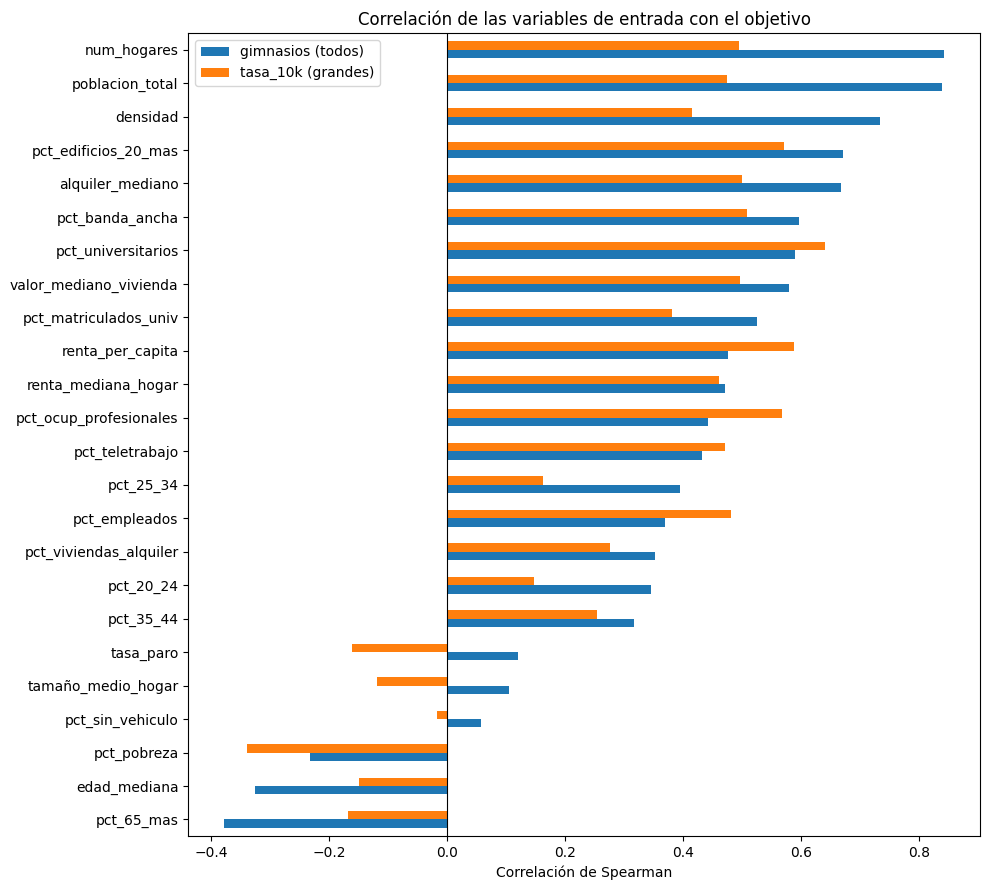

In [ ]:
tabla_corr = pd.DataFrame({
    "gimnasios (todos)": corr_total,
    "tasa_10k (grandes)": corr_tasa,
}).sort_values("gimnasios (todos)")

tabla_corr.plot.barh(figsize=(10, 9))
plt.axvline(0, color="black", linewidth=0.8)   # línea en 0 para separar positivas y negativas
plt.xlabel("Correlación de Spearman")
plt.title("Correlación de las variables de entrada con el objetivo")
plt.tight_layout()
plt.show()

In [ ]:
#Valores exactos de las correlaciones del gráfico
tabla_corr.round(2)

La correlación de Spearman muestra dos lecturas distintas. Con el número bruto de gimnasios dominan las variables de tamaño y urbanización (hogares, población, densidad, edificios de 20 o más viviendas y alquiler mediano), con correlaciones entre $\rho = 0{,}67$ y $\rho = 0{,}84$, lo que refleja que los condados grandes concentran más gimnasios. Al pasar a la tasa por $10\,000$ habitantes en condados grandes, el protagonismo pasa al perfil socioeconómico: porcentaje de universitarios, renta per cápita y ocupaciones profesionales ($\rho$ entre $0{,}57$ y $0{,}64$), mientras que la pobreza y el porcentaje de mayores de 65 se asocian negativamente ($\rho = -0{,}34$ y $\rho = -0{,}17$). Los grupos de edad jóvenes tienen menos peso del esperado y la ausencia de vehículo no muestra relación. Estas asociaciones están solapadas entre sí, por lo que se estudiará la colinealidad antes de modelar.

## 6.2 Correlación entre variables de entrada

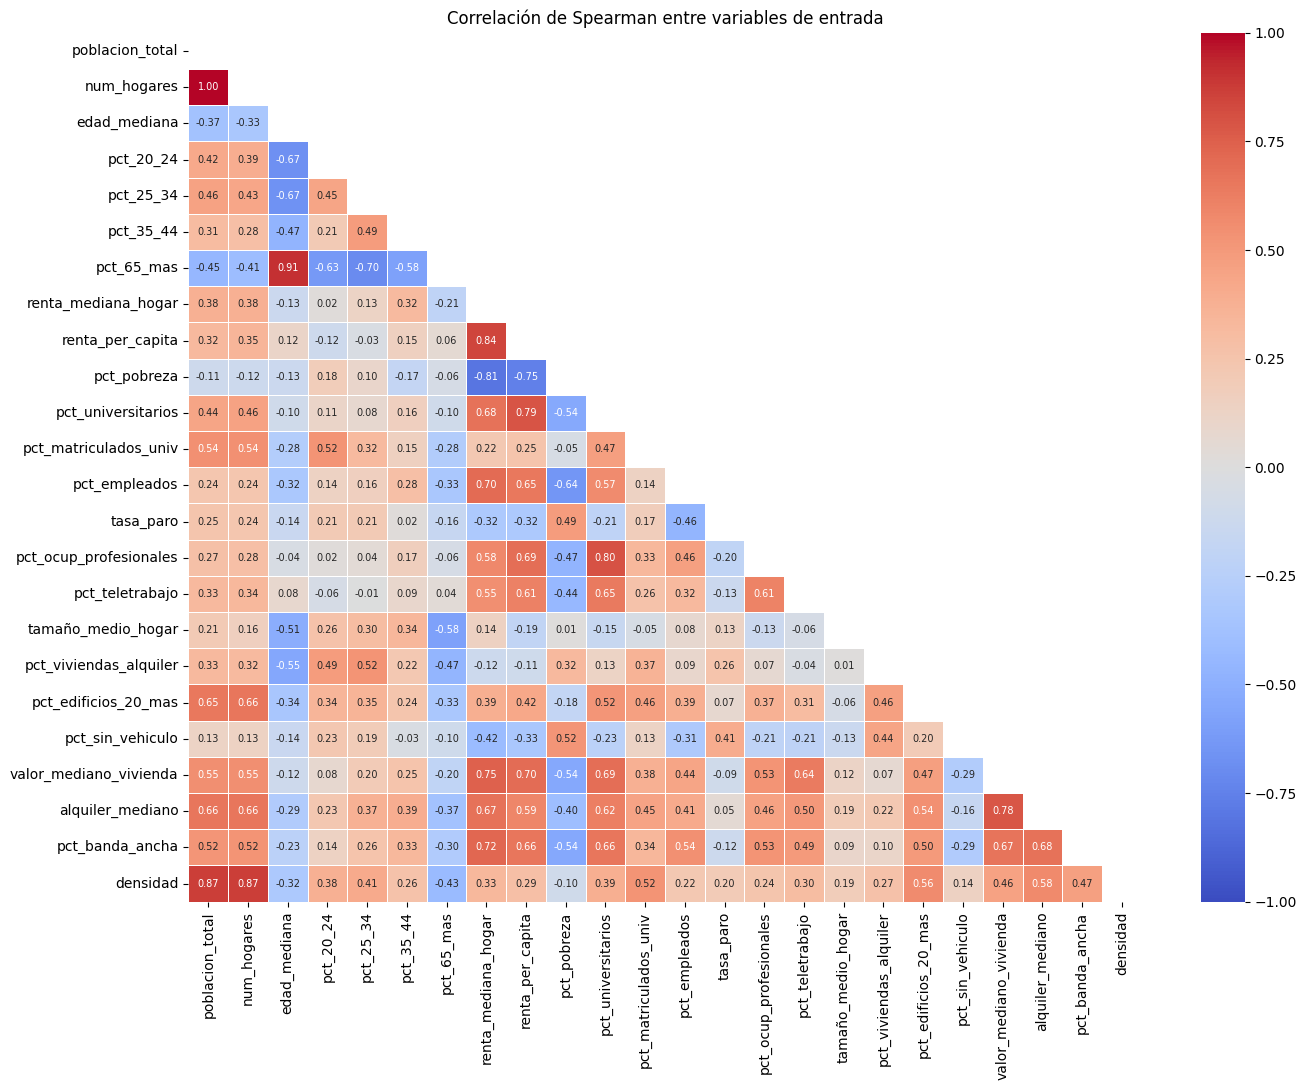

In [ ]:
corr = df[variables].corr(method="spearman")           # correlación de Spearman entre todas las variables de entrada

mascara = np.triu(np.ones_like(corr, dtype=bool))      # oculta el triángulo superior, que repite el inferior

plt.figure(figsize=(14, 11))
sns.heatmap(
    corr, mask=mascara,
    annot=True, fmt=".2f", annot_kws={"size": 7},      # números pequeños para que quepan
    cmap="coolwarm", vmin=-1, vmax=1,                  # rojo = positiva, azul = negativa
    linewidths=0.5,
)
plt.title("Correlación de Spearman entre variables de entrada")
plt.tight_layout()
plt.show()

El mapa de calor muestra que varias variables aportan información casi repetida. `num_hogares` y `poblacion_total` tienen una correlación de $\rho = 1{,}00$, `edad_mediana` y `pct_65_mas` de $0{,}91$, y las dos rentas (mediana del hogar y per cápita) de $0{,}84$. La pobreza se relaciona de forma inversa con la renta mediana del hogar ($\rho = -0{,}81$), y densidad se parece mucho a la población y a los hogares ($0{,}87$). Se distinguen tres bloques: tamaño y urbanización, nivel económico y educativo, y estructura de edad. Esto obliga a seleccionar variables antes de modelar, eligiendo en cada grupo la más fácil de interpretar y descartando las que se repiten.

## 6.3 Diagramas de dispersión

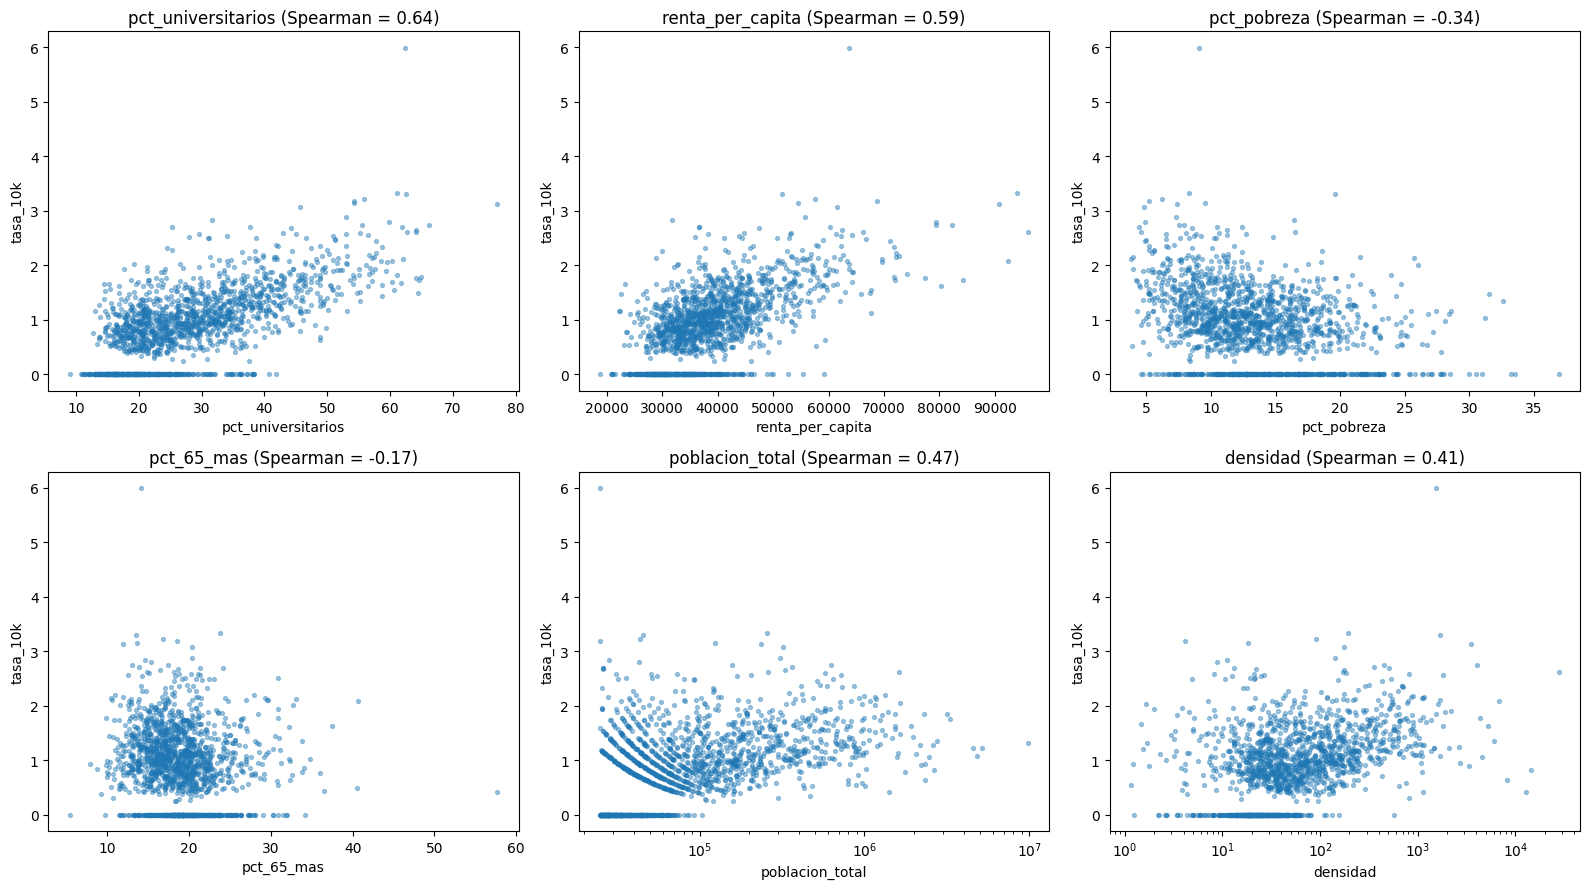

In [ ]:
claves = ["pct_universitarios", "renta_per_capita", "pct_pobreza", "pct_65_mas", "poblacion_total", "densidad"]
escala_log = ["poblacion_total", "densidad"]   #variables con valores muy dispares: eje x en log

fig, ejes = plt.subplots(2, 3, figsize=(16, 9))

for ax, var in zip(ejes.flatten(), claves):
    ax.scatter(grandes[var], grandes["tasa_10k"], s=8, alpha=0.4)   #un punto por condado alpha da transparencia para ver dónde se acumulan
    if var in escala_log:
        ax.set_xscale("log")
    r = grandes[var].corr(grandes["tasa_10k"], method="spearman")   #Spearman de esa pareja para ponerlo en el título
    ax.set_title(f"{var} (Spearman = {r:.2f})")
    ax.set_xlabel(var)
    ax.set_ylabel("tasa_10k")

plt.tight_layout()
plt.show()

Los diagramas de dispersión confirman las correlaciones. La tasa de gimnasios aumenta con el porcentaje de universitarios y la renta per cápita, disminuye ligeramente con la pobreza y apenas varía con el porcentaje de mayores de 65. Con la población, la tasa sube hasta unos 100.000 habitantes y luego se estabiliza, y la dispersión se reduce en los condados más grandes. Las curvas de puntos que se ven en la población reflejan que el objetivo es un conteo. También destaca un condado con una tasa en torno a $6$, que miro con más detalle a continuación.

In [ ]:
#Ordeno los condados grandes de mayor a menor tasa
ordenados = grandes.sort_values("tasa_10k", ascending=False)
#Muestro los 5 con mayor tasa
print(ordenados.head(5)[["NAME", "gimnasios", "poblacion_total", "tasa_10k"]])

#Me quedo con los condados grandes que no tienen gimnasios
sin_gimnasios = grandes[grandes["gimnasios"] == 0]
print("Condados grandes sin gimnasios:", len(sin_gimnasios))
print("Condados grandes en total:", len(grandes))
#Porcentaje de condados grandes sin gimnasios
print("Porcentaje sin gimnasios:", len(sin_gimnasios) / len(grandes) * 100)

                                NAME  gimnasios  poblacion_total  tasa_10k
2926          Fairfax city, Virginia         15            25026  5.993766
207         Marin County, California         86           257969  3.333734
2920  Charlottesville city, Virginia         15            45437  3.301274
496           Oconee County, Georgia         14            43551  3.214622
299           Routt County, Colorado          8            25084  3.189284
Condados grandes sin gimnasios: 372
Condados grandes en total: 1617
Porcentaje sin gimnasios: 23.00556586270872


El condado atípico es Fairfax city, una ciudad de apenas 25.000 habitantes. Probablemente sus gimnasios atienden también a población de fuera de sus límites. El resto de los condados con mayor tasa son zonas con rentas altas, universidades o turismo, lo que encaja con las correlaciones. Además, 372 de los 1.617 condados grandes (23 %) no tienen ningún gimnasio, así que el exceso de ceros persiste incluso sin los condados pequeños.

# 7. Geografía: región y estado

## 7.1 Codificación de la región

La única variable categórica es el estado. Para poder usarla en un análisis hay que convertirla en números. Una columna por estado crearía 50 columnas nuevas, casi todas con muy pocos condados, así que agrupo los estados en las cuatro regiones del Censo de EE. UU.: Noreste, Medio Oeste, Sur y Oeste. Así se conserva la información geográfica con solo tres columnas nuevas. El estado se mantiene sin codificar para poder comparar la oferta de gimnasios entre estados y para usarlo más adelante al agrupar los condados en la validación.

In [ ]:
regiones = {
    "Noreste": ["Connecticut", "Maine", "Massachusetts", "New Hampshire", "Rhode Island", "Vermont",
                "New Jersey", "New York", "Pennsylvania"],
    "Medio Oeste": ["Illinois", "Indiana", "Michigan", "Ohio", "Wisconsin", "Iowa", "Kansas",
                    "Minnesota", "Missouri", "Nebraska", "North Dakota", "South Dakota"],
    "Sur": ["Delaware", "District of Columbia", "Florida", "Georgia", "Maryland", "North Carolina",
            "South Carolina", "Virginia", "West Virginia", "Alabama", "Kentucky", "Mississippi",
            "Tennessee", "Arkansas", "Louisiana", "Oklahoma", "Texas"],
    "Oeste": ["Arizona", "Colorado", "Idaho", "Montana", "Nevada", "New Mexico", "Utah", "Wyoming",
              "Alaska", "California", "Hawaii", "Oregon", "Washington"],
}

#Diccionario estado -> región
region_de_estado = {}
for region, estados in regiones.items():
    for estado in estados:
        region_de_estado[estado] = region

df["region"] = df["estado"].map(region_de_estado)
print("Condados sin región:", df["region"].isna().sum())   #debe ser 0
print(df["region"].value_counts())

#One-hot de la región (se elimina una categoría para no duplicar información)
region_dummies = pd.get_dummies(df["region"], prefix="region", drop_first=True)
df = pd.concat([df, region_dummies], axis=1)
region_dummies.head()

Condados sin región: 0
region
Sur            1422
Medio Oeste    1055
Oeste           449
Noreste         218
Name: count, dtype: int64


,region_Noreste,region_Oeste,region_Sur
0,False,False,True
1,False,False,True
2,False,False,True
3,False,False,True
4,False,False,True


## 7.2 Oferta por región y estado

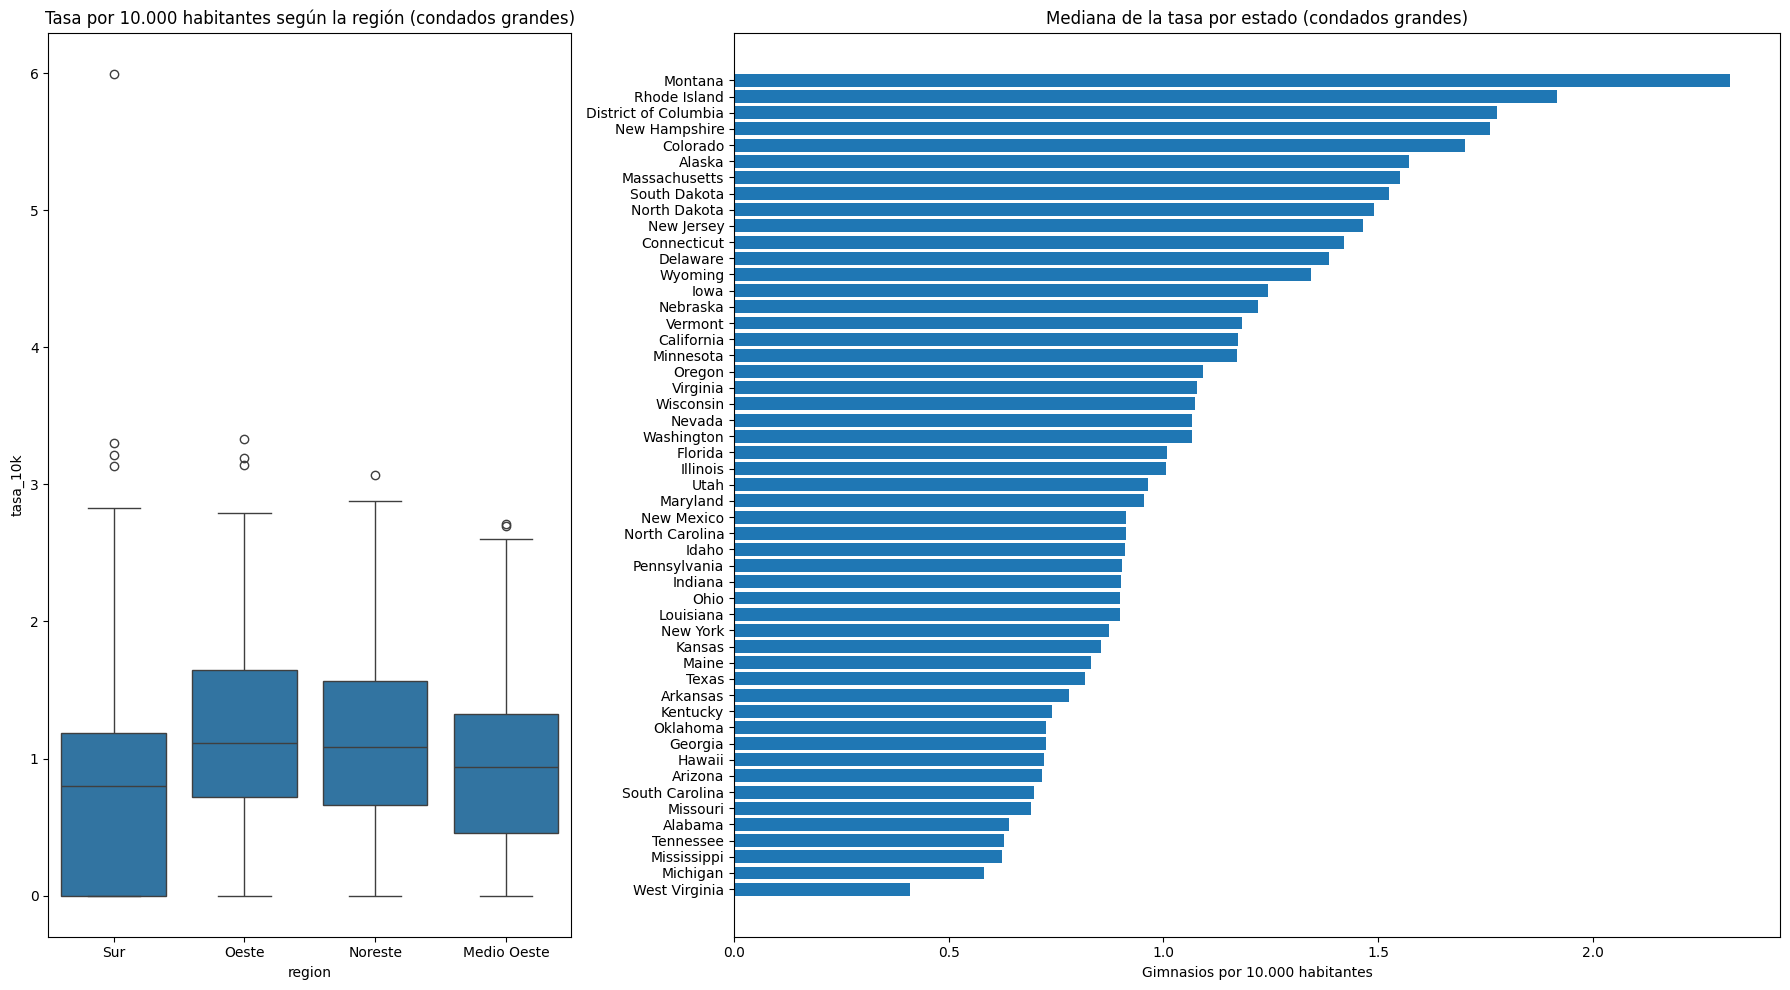

In [ ]:
grandes = df[df["grande"]]   #actualizo grandes para que incluya la región

fig, ejes = plt.subplots(1, 2, figsize=(18, 10), gridspec_kw={"width_ratios": [1, 2]})

sns.boxplot(data=grandes, x="region", y="tasa_10k", ax=ejes[0])
ejes[0].set_title("Tasa por 10.000 habitantes según la región (condados grandes)")

#Mediana de la tasa por estado
mediana_estado = grandes.groupby("estado")["tasa_10k"].median().sort_values()
ejes[1].barh(mediana_estado.index, mediana_estado.values)
ejes[1].set_title("Mediana de la tasa por estado (condados grandes)")
ejes[1].set_xlabel("Gimnasios por 10.000 habitantes")

plt.tight_layout()
plt.show()

In [ ]:
#Mediana de la tasa por región
print(grandes.groupby("region")["tasa_10k"].median().round(2))

region
Medio Oeste    0.94
Noreste        1.08
Oeste          1.12
Sur            0.80
Name: tasa_10k, dtype: float64


In [ ]:
#Porcentaje de condados grandes sin gimnasios en cada región
sin_region = grandes[grandes["gimnasios"] == 0]["region"].value_counts()
total_region = grandes["region"].value_counts()
print((sin_region / total_region * 100).round(1))

La oferta de gimnasios por habitante cambia según la zona del país. La mediana es más alta en el Oeste ($1{,}12$) y el Noreste ($1{,}08$), intermedia en el Medio Oeste ($0{,}94$) y más baja en el Sur ($0{,}80$), donde casi el 30 % de los condados grandes no tiene ningún gimnasio. Sin embargo, las cajas de las regiones se solapan bastante, así que hay más diferencias entre condados de una misma región que entre regiones. Por estados, destacan con mayor oferta Montana, Rhode Island, el Distrito de Columbia, New Hampshire y Colorado, y con menor oferta West Virginia, Michigan, Mississippi, Tennessee y Alabama. En los estados con muy pocos condados grandes, como el Distrito de Columbia, la mediana es poco fiable. En conjunto, la geografía influye, pero el perfil de cada condado parece pesar más.

## 7.3 Mapa de la oferta

Ya hemos visto que la oferta de gimnasios está muy concentrada, y qué variables se relacionan con ella, falta ver dónde está.

Para eso represento los condados en un mapa interactivo, con un punto por condado en su centro geográfico. El color indica los gimnasios por cada 10.000 habitantes y el tamaño, la población.

Solo dibujo los condados con 25.000 habitantes o más, porque en los pequeños la tasa es muy inestable y daría una imagen engañosa. La escala de color se recorta en el percentil 95 para que unos pocos valores extremos no aplasten al resto.

Con el mapa quiero comprobar dos cosas. Primera, si las zonas con más oferta coinciden con el perfil que salía en las correlaciones (zonas urbanas, con estudios y rentas altas). Segunda, si los condados vecinos tienen valores parecidos. Si es así, en el modelado habrá que validar agrupando por estado para no obtener resultados demasiado optimistas.

In [ ]:
#Centro de cada condado: se calcula en una proyección en metros (5070) y se vuelve a latitud/longitud (4326)
centros = geo.to_crs(epsg=5070).centroid.to_crs(epsg=4326)
puntos = pd.DataFrame({"fips": geo["GEOID"], "lon": centros.x, "lat": centros.y})

#Añado las coordenadas a df y me quedo con los condados grandes, donde la tasa es fiable
mapa = df.merge(puntos, on="fips")
mapa = mapa[mapa["grande"]]

In [ ]:
#Mapa interactivo de plotly: GitHub no lo muestra, ejecuta el cuaderno para verlo
fig = px.scatter_map(
    mapa,
    lat="lat", lon="lon",
    color="tasa_10k",                  #color = gimnasios por 10.000 habitantes
    size="poblacion_total", size_max=15,   #tamaño = población
    hover_name="NAME",                 #nombre del condado al pasar el ratón
    hover_data={"gimnasios": True, "poblacion_total": True, "lat": False, "lon": False},
    color_continuous_scale="Viridis",
    range_color=[0, mapa["tasa_10k"].quantile(0.95)],   #escala hasta el percentil 95 para que los extremos no estropeen los colores
    map_style="carto-voyager",        #fondo de mapa
    center={"lat": 39.5, "lon": -98.35},   #se inicia en centro de EE. UU.
    zoom=3,
    title="Gimnasios por 10.000 habitantes (condados con 25.000 habitantes o más)",
)

fig.show()

# 8. Selección de variables

El mapa de calor mostró que varias variables aportan casi la misma información. Para no contar dos veces lo mismo, elimino una de cada pareja muy correlacionada y me quedo con la que tiene más sentido o se relaciona más con el objetivo:

- `num_hogares`: es casi idéntica a `poblacion_total` ($\rho = 1{,}00$). Me quedo con la población.
- `renta_mediana_hogar`: tiene $\rho = 0{,}84$ con `renta_per_capita`, y esta última se relaciona más con la tasa de gimnasios ($0{,}59$ frente a $0{,}46$). Me quedo con la renta per cápita.
- `pct_ocup_profesionales`: tiene $\rho = 0{,}80$ con `pct_universitarios`, que se relaciona más con la tasa ($0{,}64$). Me quedo con el porcentaje de universitarios.
- `edad_mediana`: tiene $\rho = 0{,}91$ con `pct_65_mas`, que es más fácil de interpretar. Me quedo con el porcentaje de mayores de 65.

In [ ]:
#Variables que elimino por repetir información de otra
eliminar = ["num_hogares", "renta_mediana_hogar", "pct_ocup_profesionales", "edad_mediana"]

#Me quedo con el resto
variables_finales = variables.drop(eliminar)
print(len(variables_finales))   #deben ser 20

#Compruebo qué parejas siguen por encima de 0,7 de correlación
corr_final = df[variables_finales].corr(method="spearman")
for i in range(len(corr_final)):
    for j in range(i):
        valor = corr_final.iloc[i, j]
        if abs(valor) > 0.7:
            print(corr_final.index[i], "-", corr_final.columns[j], round(valor, 2))

20
pct_65_mas - pct_25_34 -0.7
pct_pobreza - renta_per_capita -0.75
pct_universitarios - renta_per_capita 0.79
alquiler_mediano - valor_mediano_vivienda 0.78
densidad - poblacion_total 0.87


Tras eliminar esas cuatro variables siguen quedando cinco parejas con correlación alta: densidad y población ($\rho = 0{,}87$), renta per cápita con universitarios ($0{,}79$) y con pobreza ($-0{,}75$), valor de la vivienda y alquiler ($0{,}78$) y mayores de 65 con el grupo de 25-34 años ($-0{,}70$). Las mantengo porque miden cosas distintas: la densidad indica lo urbano que es el condado y la población cuánta gente tiene, y el valor de la vivienda y el alquiler reflejan mercados distintos (comprar y alquilar). Tampoco llegan a la repetición casi total de las parejas eliminadas, que estaban entre $0{,}80$ y $1{,}00$. Por tanto, el resultado final son $20$ variables de entrada.

# 9. Preparación para la clusterización

Antes de agrupar los condados preparo los datos. Para cada variable uso la versión logarítmica si el log reducía su sesgo y la original en el resto. Los nulos son los $11$ condados pequeños que vimos antes, y los relleno con la mediana de cada variable.

Por último escalo todas las variables para que tengan media $0$ y desviación típica $1$:

$$z = \frac{x - \mu}{\sigma}$$

Lo hago porque K-means trabaja con distancias y, sin escalar, las variables con valores grandes (como la renta) dominarían sobre los porcentajes. Ni el número de gimnasios ni la tasa entran en esta tabla: se usarán solo para describir los grupos.

In [ ]:
#Para cada variable uso la versión log si la creé y la original si no
columnas = []
for v in variables_finales:
    if v in vars_log:
        columnas.append("log_" + v)
    else:
        columnas.append(v)

X = df[columnas].copy()

#Relleno los nulos con la mediana de cada columna
X = X.fillna(X.median())

#Escalo para que cada variable tenga media 0 y desviación 1
scaler = StandardScaler()
x_escalada = scaler.fit_transform(X)

#Compruebo que no quedan nulos y que la media es 0 y la desviación 1
print("Nulos:", np.isnan(x_escalada).sum())
print("Media:", x_escalada.mean(axis=0).round(2))
print("Desviación:", x_escalada.std(axis=0).round(2))

Nulos: 0
Media: [-0. -0.  0.  0. -0.  0. -0.  0. -0.  0.  0. -0. -0. -0.  0. -0. -0. -0.
 -0. -0.]
Desviación: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


# 10. Clusterización de los condados

## 10.1 K-means y número de grupos

Hasta ahora he comparado las variables de una en una o por parejas. Para tener una visión de conjunto uso la clusterización, una técnica que agrupa automáticamente los condados que se parecen entre sí en todas sus características a la vez, sin decirle de antemano qué grupos buscar. Es lo que se llama aprendizaje no supervisado, porque no se usa el objetivo: ni el número de gimnasios ni la tasa entran en el cálculo, solo las $20$ variables de entrada. Después uso el número de gimnasios para describir cada grupo.

Lo hago por dos motivos: para comprobar si existen perfiles de condado diferenciados, como urbanos con rentas altas frente a rurales y pequeños, y para ver si la oferta de gimnasios cambia de un perfil a otro, lo que ayudaría a localizar dónde hay menos oferta de la esperada.

El método que uso es K-means. Coloca $K$ puntos centrales y asigna cada condado al más cercano, de modo que los condados que quedan juntos forman un grupo.

Antes hay que decidir cuántos grupos formar, y para eso pruebo de $K = 2$ a $K = 8$. Para comparar uso la inercia, que mide lo cerca que están los condados del centro de su grupo:

$$\text{inercia} = \sum_{i=1}^{n} \lVert x_i - c_{g(i)} \rVert^2$$

donde $x_i$ es el condado $i$ y $c_{g(i)}$ el centro de su grupo. Cuanto más baja, más parecidos son los condados dentro de cada grupo. La inercia siempre baja al añadir grupos, así que no basta con quedarse con el valor más bajo. Lo que se busca es el codo de la gráfica: el punto donde la curva deja de bajar rápido y añadir más grupos ya mejora poco.

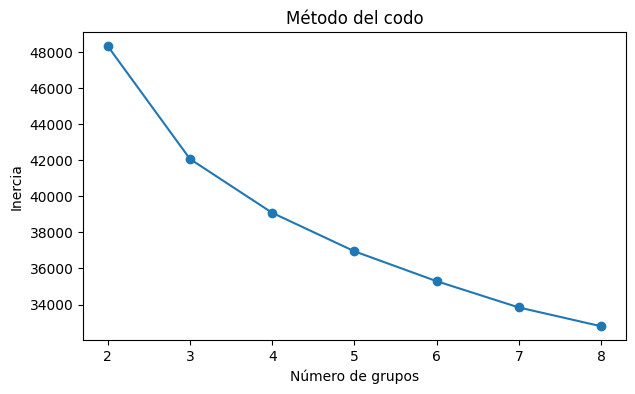

In [ ]:
inercias = []        #aquí guardo la inercia de cada prueba
ks = range(2, 9)     #pruebo de 2 a 8 grupos

for k in ks:
    modelo = KMeans(n_clusters=k, n_init=10, random_state=42)   #n_init=10 repite el algoritmo 10 veces y se queda con el mejor, random_state hace que el resultado sea siempre el mismo
    modelo.fit(x_escalada)                                        #agrupa los condados con las 20 variables escaladas
    inercias.append(modelo.inertia_)                            #guardo la inercia de este número de grupos

#Gráfica del codo
plt.figure(figsize=(7, 4))
plt.plot(ks, inercias, marker="o")
plt.xlabel("Número de grupos")
plt.ylabel("Inercia")
plt.title("Método del codo")
plt.show()

Por lo que se puede observar, la curva es bastante suave y casi continua. Aun así, hay una caída más fuerte entre $K = 2$ y $K = 3$, y a partir de $K = 4$ la caída es mucho más lenta y no mejora mucho. Por tanto, me quedo con $K = 4$ porque permite interpretar perfiles distintos sin crear demasiados grupos.

## 10.2 Perfil de los grupos

In [ ]:
K = 4   #número de grupos elegido

modelo = KMeans(n_clusters=K, n_init=10, random_state=42)
df["cluster"] = modelo.fit_predict(x_escalada)   #fit_predict agrupa y devuelve el grupo de cada condado (0, 1, 2 o 3)

df["sin_gimnasios"] = df["gimnasios"] == 0     #True si el condado no tiene gimnasios

#Perfil de cada grupo: mediana de algunas variables
perfil = df.groupby("cluster")[["poblacion_total", "densidad", "renta_per_capita", "pct_universitarios",
                                "pct_65_mas", "pct_pobreza", "pct_edificios_20_mas"]].median().round(1)

#Número de condados de cada grupo y porcentaje sin gimnasios
perfil["n_condados"] = df["cluster"].value_counts()
perfil["pct_sin_gimnasios"] = (df.groupby("cluster")["sin_gimnasios"].mean() * 100).round(1)

#Tasa mediana de gimnasios por 10.000 habitantes, solo en condados grandes
perfil["tasa_mediana_grandes"] = df[df["grande"]].groupby("cluster")["tasa_10k"].median().round(2)
perfil

,poblacion_total,densidad,renta_per_capita,pct_universitarios,pct_65_mas,pct_pobreza,pct_edificios_20_mas,n_condados,pct_sin_gimnasios,tasa_mediana_grandes
cluster,,,,,,,,,,
0,231085.5,167.5,45988.5,38.9,16.6,9.6,7.2,538,4.3,1.37
1,8882.0,4.5,37237.0,23.0,24.2,11.0,0.9,847,88.7,0.65
2,48213.5,33.6,35126.0,23.4,18.7,13.1,2.8,916,33.2,0.80
3,16406.0,12.0,28227.0,15.6,19.9,19.4,0.8,843,89.2,0.00


Los cuatro grupos tienen perfiles distintos. El grupo 0 es el urbano y de renta alta. Tiene 538 condados con unos 231.000 habitantes de mediana, 167 habitantes por km², un 39 % de universitarios y la renta per cápita más alta. Solo el 4 % no tiene gimnasios y su tasa en condados grandes es la más alta, $1{,}37$ por cada 10.000 habitantes.

El grupo 2 es el intermedio. Tiene 916 condados con unos 48.000 habitantes y renta y estudios medios. El 33 % no tiene gimnasios y su tasa es $0{,}80$.

Los grupos 1 y 3 son rurales y pequeños, y en los dos cerca del 89 % de los condados no tiene gimnasios. El grupo 1 tiene 847 condados con unos 9.000 habitantes y es el más envejecido, con un 24 % de mayores de 65 años. El grupo 3 tiene 843 condados con unos 16.000 habitantes y es el que tiene más pobreza, un 19 %, y menos renta y universitarios. Su tasa mediana en condados grandes es 0, es decir, más de la mitad de sus condados grandes no tiene ninguno.

Los grupos separan bien los condados por tamaño y urbanización, y entre los rurales distinguen el envejecido del más pobre. La tasa baja del grupo urbano a los rurales y es la más baja en el grupo con más pobreza, lo que encaja con lo visto antes: más estudios y renta se asocian con más gimnasios y más pobreza con menos.

## 10.3 Mapa de los grupos

In [ ]:
#Mapa interactivo de plotly: GitHub no lo muestra, ejecuta el cuaderno para verlo
#Mapa con todos los condados (puntos ya está creado antes)
mapa_grupos = df.merge(puntos, on="fips")
mapa_grupos["cluster"] = mapa_grupos["cluster"].astype(str)   #texto para que plotly use un color por grupo

fig = px.scatter_map(
    mapa_grupos,
    lat="lat", lon="lon",
    color="cluster",                     #color = grupo
    size="poblacion_total", size_max=15, #tamaño = población
    hover_name="NAME",
    hover_data={"gimnasios": True, "poblacion_total": True, "lat": False, "lon": False},
    category_orders={"cluster": ["0", "1", "2", "3"]},
    map_style="carto-voyager",
    center={"lat": 39.5, "lon": -98.35},
    zoom=3,
    title="Grupos de condados (K-means con 4 grupos)",
)
fig.update_layout(height=700)
fig.show()

## 10.4 Grupos y regiones

In [ ]:
#Qué porcentaje de cada grupo cae en cada región
pd.crosstab(df["cluster"], df["region"], normalize="index").round(2) * 100

region,Medio Oeste,Noreste,Oeste,Sur
cluster,,,,
0,22.0,18.0,23.0,37.0
1,55.0,3.0,19.0,22.0
2,36.0,9.0,13.0,41.0
3,16.0,1.0,5.0,78.0


Los grupos tienen una distribución geográfica distinta. El grupo rural con pobreza está muy concentrado en el Sur, donde está el 78 % de sus condados. El grupo rural envejecido se concentra sobre todo en el Medio Oeste, con un 55 %, y casi no aparece en el Noreste. El grupo urbano de renta alta está más repartido, aunque destaca el Noreste, que tiene el 18 % de sus condados a pesar de ser la región con menos condados. El grupo intermedio se reparte sobre todo entre el Sur y el Medio Oeste, con un 41 % y un 36 %. Esto concuerda con lo visto antes. La región influye, pero el perfil del condado importa más, porque cada región mezcla varios tipos de condado.

# 11. Resultados

## 11.1 Discusión de los resultados

El estudio cubre 3.144 condados de 51 estados con 24 variables de entrada que elegí por criterio propio. Los nulos fueron muy pocos y estaban en condados muy pequeños donde ACS no publica algunas medianas.

El número de gimnasios es un conteo con muchos ceros y muy desigual. El 58 % de los condados no tiene ninguno y el 10 % de los condados concentra casi el 79 % de los gimnasios. Los ceros se dan sobre todo en condados pequeños, pero también en un 23 % de los grandes, por eso las tasas por habitante solo se comparan en condados grandes.

Con el número bruto de gimnasios dominan el tamaño y la urbanización. Con la tasa por 10.000 habitantes gana peso el perfil socioeconómico. Más universitarios y más renta se asocian con más gimnasios, y más pobreza con menos. Los grupos de edad jóvenes pesan menos de lo esperado y la ausencia de vehículo no muestra relación. Los diagramas de dispersión muestran que estas relaciones son graduales y con mucho ruido.

Varias variables medían casi lo mismo, así que eliminé cuatro y me quedé con 20 variables de entrada.

La región influye. El Oeste y el Noreste tienen las tasas medianas más altas y el Sur la más baja. Aun así hay mucha variación entre condados de un mismo estado, así que el perfil del condado importa más que su ubicación.

La clusterización separa cuatro perfiles: un grupo urbano de renta alta donde casi todos los condados tienen gimnasios, un grupo intermedio y dos grupos rurales donde cerca del 89 % no tiene ninguno. Uno de los rurales es envejecido y está sobre todo en el Medio Oeste, y el otro tiene más pobreza y está sobre todo en el Sur. La curva del codo era suave, así que los condados forman más bien un continuo y los grupos sirven para describirlos más que para separarlos de forma natural.

Como limitaciones, CBP solo cuenta establecimientos con empleados, así que no recoge gimnasios sin plantilla. Los datos de ACS son estimaciones de cinco años y tienen poca precisión en condados pequeños. Además, los límites administrativos distorsionan algunos casos, como Fairfax city. Las relaciones encontradas son asociaciones y no demuestran causalidad.

## 11.2 Hipótesis y objetivo para el modelado

Con lo visto planteo estas hipótesis:

1. Más población y más urbanización implican más gimnasios. Es la relación más fuerte y se espera que domine el modelo.
2. A igualdad de tamaño, los condados con más universitarios y más renta per cápita tienen una tasa de gimnasios más alta.
3. La pobreza y un mayor porcentaje de mayores de 65 años se asocian con una tasa más baja.
4. Los grupos de edad jóvenes aportan menos de lo esperado y el porcentaje de hogares sin vehículo no aporta nada una vez se tiene en cuenta la urbanización.
5. La región y el estado aportan información extra y, como los condados vecinos se parecen, la validación debe agrupar por estado.

El objetivo predictivo es predecir el número de gimnasios de cada condado a partir de sus características. Como es un conteo con muchos ceros, usaré un modelo de conteo, que solo predice números enteros desde 0 en adelante y no valores negativos o decimales como haría una regresión normal. En concreto probaré la binomial negativa, que sirve cuando los datos están muy dispersos como aquí. Lo compararé con un modelo de árboles, que predice haciendo preguntas sucesivas sobre las variables, por ejemplo si el condado supera cierta población o cierto porcentaje de universitarios. El de conteo es más fácil de interpretar y el de árboles suele captar mejor las relaciones complicadas, así que al compararlos veo si compensa la complejidad extra. Con el modelo se podrán detectar los condados con menos gimnasios de los que se esperarían por su perfil, que son los posibles espacios vacíos de mercado.

Las entradas serán las 20 variables seleccionadas, con su versión logarítmica donde corresponda, y la región codificada. No se usarán ni la tasa por 10.000 habitantes ni la variable grande, porque se calculan a partir del objetivo y filtrarían la respuesta al modelo.

## 11.3 Guardado de los datos

In [ ]:
#Guardo el dataframe con las variables ya preparadas para usarlo en el modelado
df.to_csv(ruta + "datos_eda.csv", index=False)